In [1]:
# ideal var is 95 %
# n_components always < no of features
# check with diff n of components  and their percentage of max var      check which cols comes in each component

In [2]:
 
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np 
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 

In [18]:
df = pd.read_csv('../datasets/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [28]:

 
# select only the numeric cols 
numeric_cols = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age']

# handline missing vals 
imputer =  SimpleImputer(strategy='mean')
data_imputed = imputer.fit_transform(df[numeric_cols])

data_clean = pd.DataFrame(data_imputed, columns=numeric_cols)

# standardize (import for PCA)
scaler=  StandardScaler()
data_scaled = scaler.fit_transform(data_clean) 


# Apply PCA 
pca = PCA(n_components=5)
data_pca = pca.fit_transform(data_scaled)


# check how much information each components keeps 
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print(explained_variance)
print(cumulative_variance)



[0.26179749 0.21640127 0.12870373 0.10944113 0.09529305]
[0.26179749 0.47819876 0.60690249 0.71634362 0.81163667]


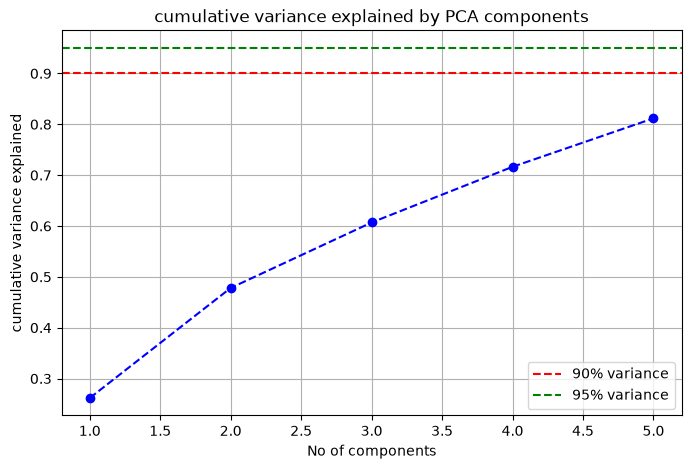

In [29]:
# plot cumulative variance
plt.figure(figsize=(8,5)) 
plt.plot(range(1,len(cumulative_variance) +1 ), cumulative_variance, marker = 'o', ls='--', color='b')
plt.title('cumulative variance explained by PCA components')
plt.xlabel('No of components')
plt.ylabel('cumulative variance explained')
plt.axhline(y = 0.9, color = 'r', ls='--', label='90% variance')
plt.axhline(y = 0.95, color = 'g', ls='--', label='95% variance')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#PRINT VARIANCE INFO
print('Explained vairance ratio:')
print(explained_variance.round(3))
print('\nCumulative vairance ')
print(cumulative_variance.round(3))



Explained vairance ratio:
[0.262 0.216 0.129 0.109 0.095]

Cumulative vairance 
[0.262 0.478 0.607 0.716 0.812]


In [38]:
# find feature contributions (looadings)  # shows the weights of feature in that respective principal component
loadings  = pd.DataFrame(
    pca.components_.T, # transpose to get feature as rows
    columns=[f'PC{i+1}' for i in range(pca.n_components_)],
    index=numeric_cols
)
print('\nFeature loading: \n',loadings.round(3))


Feature loading: 
                             PC1    PC2    PC3    PC4    PC5
Pregnancies               0.128  0.594  0.013  0.081  0.476
Glucose                   0.393  0.174 -0.468 -0.404 -0.466
BloodPressure             0.360  0.184  0.535  0.056 -0.328
SkinThickness             0.440 -0.332  0.238  0.038  0.488
Insulin                   0.435 -0.251 -0.337 -0.350  0.347
BMI                       0.452 -0.101  0.362  0.054 -0.253
DiabetesPedigreeFunction  0.271 -0.122 -0.433  0.834 -0.120
Age                       0.198  0.621 -0.075  0.071  0.109


In [34]:
# use prinpal components for logistic regression 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

index_of_95 = np.argmax(cumulative_variance >= 0.95)
index_of_95

np.int64(0)

In [35]:
# np.argmax returns the index of the first 'True' . if no True is founf it return 0 . we must check if the 95% target was actually reached at that iundex. 

if cumulative_variance[index_of_95] >= 0.95:
    #if the target was reached , n_opt is the index+1 (to correct for 0 indexing)
    n_opt = index_of_95 +1
else:
    # if the target was NOT reached, use all variable components. 
    n_opt = len(explained_variance)

print(n_opt)

5


In [40]:
# use the optimally reduced data for modelling 
X_pca_reduced = data_pca[:, :n_opt]
y = df['Outcome']

x_train, x_test, y_train, y_test = train_test_split(X_pca_reduced, y, test_size=0.3, random_state=42, stratify=y)

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(x_train, y_train)

y_pred = log_reg.predict(x_test)

accuracy = log_reg.predict(y_test, y_pred)
print(f'Model accuracy: {accuracy:.4f}')

TypeError: LinearClassifierMixin.predict() takes 2 positional arguments but 3 were given